# Validación estadística de la superioridad

## Protocolo común
- **Mismas particiones, misma semilla (2026), mismo preprocesamiento** para ATER y para los 7 benchmarks (3 tradicionales y 4 de Machine Learning).
- **Validación anidada temporal:** el bucle externo son los folds 1 a 4 de la validación de ventana creciente (purga de 48 h); dentro de cada uno, Optuna ajusta los hiperparámetros de ATER **solo con los folds anteriores**.
- **Prueba única:** enero 2025 – octubre 2026, 653 días. ATER se entrena con los mismos datos y los mismos expertos que los benchmarks y pronostica en línea.
- **Unidad de comparación:** la pérdida diaria (MSE de las 24 horas de cada día), que es la unidad en que se emite el pronóstico.
- **Pruebas (ruta de series de tiempo del Cuadro 3):** (1) **Model Confidence Set** con todos los modelos, (2) **Giacomini-White** condicional, (3) **Diebold-Mariano con corrección HLN**, y como complemento **Wilcoxon** de rangos con signo. Ajuste de **Holm-Bonferroni** sobre las 21 comparaciones (3 pruebas × 7 benchmarks). IC por **bootstrap estacionario** (bloque medio de 7 días) y tamaños del efecto (δ de Cliff y d de Cohen).

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, "../src"); import estilo_tablas; estilo_tablas.activar()
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 120)
R = "../resultados/"
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
ORIG = "ATER (modelo original)"
COL = {"Persistencia (misma hora de ayer)": "#9AA5A0", "Estacional (misma hora semana pasada)": "#B8C2BD", "Promedio por hora y día": "#D5DBD8",
       "Ridge (lineal)": "#5B7F96", "Random forest (relativo)": "#1F5A3A", "XGBoost (relativo)": "#C8892B",
       "Híbrido Ridge + XGBoost (residuo relativo)": "#8E4B7A", ORIG: "#C0392B"}

In [2]:
an = pd.read_csv(R + "orig_validacion_anidada.csv"); af = pd.read_csv(R + "orig_validacion_anidada_folds.csv")
print("Validación anidada temporal (bucle externo = folds 1 a 4), media ± desviación estándar:")
an.assign(MSE=lambda d: d.MSE_media.round(0).astype(int).astype(str) + " ± " + d.MSE_de.round(0).astype(int).astype(str),
          MAPE=lambda d: d.MAPE_media.round(2).astype(str) + " ± " + d.MAPE_de.round(2).astype(str))[["modelo", "MSE", "MAPE"]]

Validación anidada temporal (bucle externo = folds 1 a 4), media ± desviación estándar:


modelo,MSE,MAPE
ATER (modelo original),2097 ± 821,2.76 ± 0.42
Híbrido Ridge + XGBoost (residuo relativo),2210 ± 759,2.93 ± 0.36
Random forest (relativo),2240 ± 806,2.87 ± 0.37
XGBoost (relativo),2247 ± 793,2.87 ± 0.39
Ridge (lineal),2542 ± 856,3.22 ± 0.42
Persistencia (misma hora de ayer),5711 ± 951,4.66 ± 0.31
Estacional (misma hora semana pasada),6797 ± 2323,5.22 ± 0.68
Promedio por hora y día,12107 ± 5856,7.43 ± 1.89


In [3]:
print("MSE por fold externo:"); af.pivot(index="modelo", columns="fold", values="MSE").round(0)

MSE por fold externo:


fold,1,2,3,4
modelo,,,,
ATER (modelo original),1.809,1.349,1.967,3.264
Estacional (misma hora semana pasada),5.707,4.286,7.548,9.648
Híbrido Ridge + XGBoost (residuo relativo),1.932,1.515,2.106,3.285
Persistencia (misma hora de ayer),5.019,5.035,5.747,7.044
Promedio por hora y día,4.985,9.823,15.648,17.973
Random forest (relativo),1.935,1.500,2.146,3.380
Ridge (lineal),2.190,1.739,2.500,3.738
XGBoost (relativo),2.039,1.492,2.095,3.364


In [4]:
tp = pd.read_csv(R + "orig_prueba.csv")
tp[["modelo", "MSE", "RMSE", "MAE", "MAPE", "AUC_pico", "CSI", "mejora_vs_persistencia_%", "entrenamiento_s", "inferencia_s"]].round(3)

modelo,MSE,RMSE,MAE,MAPE,AUC_pico,CSI,mejora_vs_persistencia_%,entrenamiento_s,inferencia_s
ATER (modelo original),2.256,"47,5","32,6","2,44","0,975","0,835","65,4","32,60","0,777"
Random forest (relativo),2.347,"48,4","34,0","2,54","0,974","0,827","64,0","29,37","0,402"
XGBoost (relativo),2.417,"49,2","34,1","2,55","0,973","0,826","62,9","2,19","0,062"
Híbrido Ridge + XGBoost (residuo relativo),3.075,"55,5","42,4","3,08","0,971","0,770","52,8","0,66","0,068"
Ridge (lineal),3.569,"59,7","46,5","3,38","0,966","0,743","45,3","0,14","0,026"
Persistencia (misma hora de ayer),6.521,"80,8","58,0","4,34","0,926","0,716","0,0","0,00","0,000"
Estacional (misma hora semana pasada),8.437,"91,9","66,6","5,00","0,906","0,681","-29,4","0,00","0,000"
Promedio por hora y día,53.602,"231,5","203,1","14,44","0,831","0,000","-722,0","0,00","0,909"


## Supuestos
- **Diebold-Mariano** necesita que la serie de diferencias de pérdida sea estacionaria y usa una varianza HAC (7 rezagos) por la autocorrelación; se verifica con la prueba ADF.
- **Giacomini-White** se plantea con esquema de ventana fija (los expertos se entrenan una vez, como pide la prueba) e instrumentos $h_{t-1}=(1, d_{t-1})$; solo exige momentos finitos de $d_t$.
- **MCS** usa bootstrap estacionario (bloque medio de 7 días), así que tolera dependencia temporal.
- **Wilcoxon** supone simetría y no corrige la autocorrelación: se usa como prueba complementaria, no como una de las tres principales.

In [5]:
adf = pd.read_csv(R + "orig_adf.csv"); adf.round(4)

benchmark,ADF,p_ADF
Persistencia (misma hora de ayer),"-3,98","0,002"
Estacional (misma hora semana pasada),"-6,61","< 0,001"
Promedio por hora y día,"-2,03","0,275"
Ridge (lineal),"-7,19","< 0,001"
Random forest (relativo),"-15,14","< 0,001"
XGBoost (relativo),"-20,38","< 0,001"
Híbrido Ridge + XGBoost (residuo relativo),"-6,10","< 0,001"


 La serie de diferencias es estacionaria (ADF, p < 0,01) frente a todos los benchmarks excepto el promedio por hora y día (p = 0,27): esa comparación de Diebold-Mariano es menos confiable, pero la diferencia frente a ese modelo es de 96 % y las pruebas MCS y Giacomini-White no dependen de ese supuesto.

## Prueba 1: Model Confidence Set (Hansen, Lunde y Nason, 2011)

In [6]:
mcs = pd.read_csv(R + "orig_mcs.csv"); mcs

modelo,p_MCS,en_conjunto_10pct
Persistencia (misma hora de ayer),"< 0,001",False
Estacional (misma hora semana pasada),"< 0,001",False
Ridge (lineal),"< 0,001",False
Promedio por hora y día,"< 0,001",False
Híbrido Ridge + XGBoost (residuo relativo),"< 0,001",False
XGBoost (relativo),"< 0,001",False
Random forest (relativo),"0,005",False
ATER (modelo original),"1,000",True


 Con $\alpha=0{,}10$ (la convención del MCS), **el conjunto de modelos superiores contiene solo a ATER**: los siete benchmarks se eliminan, el random forest relativo con p = 0,005 y el XGBoost relativo con p = 0,001.

## Pruebas 2 y 3 (y complementaria): Giacomini-White, Diebold-Mariano y Wilcoxon

In [7]:
pr = pd.read_csv(R + "orig_pruebas_hipotesis.csv")
print("Hipótesis nula de cada prueba: igual desempeño (pérdida diaria esperada igual) entre ATER y el benchmark.")
print("Comparaciones totales para el ajuste de Holm:", pr.n_comparaciones.iloc[0])
pr[["prueba", "benchmark", "supuestos", "estadistico", "p_crudo", "p_holm", "conclusion"]].round(5)

Hipótesis nula de cada prueba: igual desempeño (pérdida diaria esperada igual) entre ATER y el benchmark.
Comparaciones totales para el ajuste de Holm: 21


prueba,benchmark,supuestos,estadistico,p_crudo,p_holm,conclusion
Diebold-Mariano (HLN),Persistencia (misma hora de ayer),serie de diferencias de pérdida estacionaria (ADF); varianza HAC con 7 rezagos,17,"< 0,001","< 0,001",ATER mejor (rechaza H0)
Giacomini-White condicional,Persistencia (misma hora de ayer),diferencias de pérdida con momentos finitos; esquema de ventana fija (expertos entrenados una vez),176,"< 0,001","< 0,001",ATER mejor (rechaza H0)
Wilcoxon de rangos con signo,Persistencia (misma hora de ayer),diferencias simétricas alrededor de la mediana; no corrige autocorrelación (complementaria),20.721,"< 0,001","< 0,001",ATER mejor (rechaza H0)
Diebold-Mariano (HLN),Estacional (misma hora semana pasada),serie de diferencias de pérdida estacionaria (ADF); varianza HAC con 7 rezagos,10,"< 0,001","< 0,001",ATER mejor (rechaza H0)
Giacomini-White condicional,Estacional (misma hora semana pasada),diferencias de pérdida con momentos finitos; esquema de ventana fija (expertos entrenados una vez),171,"< 0,001","< 0,001",ATER mejor (rechaza H0)
Wilcoxon de rangos con signo,Estacional (misma hora semana pasada),diferencias simétricas alrededor de la mediana; no corrige autocorrelación (complementaria),18.507,"< 0,001","< 0,001",ATER mejor (rechaza H0)
Diebold-Mariano (HLN),Promedio por hora y día,serie de diferencias de pérdida estacionaria (ADF); varianza HAC con 7 rezagos,11,"< 0,001","< 0,001",ATER mejor (rechaza H0)
Giacomini-White condicional,Promedio por hora y día,diferencias de pérdida con momentos finitos; esquema de ventana fija (expertos entrenados una vez),444,"< 0,001","< 0,001",ATER mejor (rechaza H0)
Wilcoxon de rangos con signo,Promedio por hora y día,diferencias simétricas alrededor de la mediana; no corrige autocorrelación (complementaria),1.560,"< 0,001","< 0,001",ATER mejor (rechaza H0)
Diebold-Mariano (HLN),Ridge (lineal),serie de diferencias de pérdida estacionaria (ADF); varianza HAC con 7 rezagos,10,"< 0,001","< 0,001",ATER mejor (rechaza H0)


## Intervalos y tamaños del efecto

In [8]:
ef = pr.drop_duplicates("benchmark")[["benchmark", "mejora_MSE_pct", "IC95_lo", "IC95_hi", "dias_gana_ATER_pct", "delta_cliff_pareado", "magnitud_cliff_pareado", "delta_cliff", "magnitud_cliff", "d_cohen"]]
ef.round(3)

benchmark,mejora_MSE_pct,IC95_lo,IC95_hi,dias_gana_ATER_pct,delta_cliff_pareado,magnitud_cliff_pareado,delta_cliff,magnitud_cliff,d_cohen
Persistencia (misma hora de ayer),"65,40","60,56","69,71","83,31","0,666",grande,"0,463",mediano,"0,61"
Estacional (misma hora semana pasada),"73,26","69,12","77,18","81,01","0,620",grande,"0,484",grande,"0,57"
Promedio por hora y día,"95,79","94,43","96,78","97,40","0,948",grande,"0,940",grande,"1,06"
Ridge (lineal),"36,78","28,76","44,74","78,25","0,565",grande,"0,407",mediano,"0,46"
Random forest (relativo),"3,88","1,12","6,80","62,63","0,253",pequeño,"0,073",despreciable,"0,12"
XGBoost (relativo),"6,66","3,77","9,54","61,10","0,222",pequeño,"0,068",despreciable,"0,14"
Híbrido Ridge + XGBoost (residuo relativo),"26,63","18,66","34,68","74,73","0,495",grande,"0,343",mediano,"0,40"


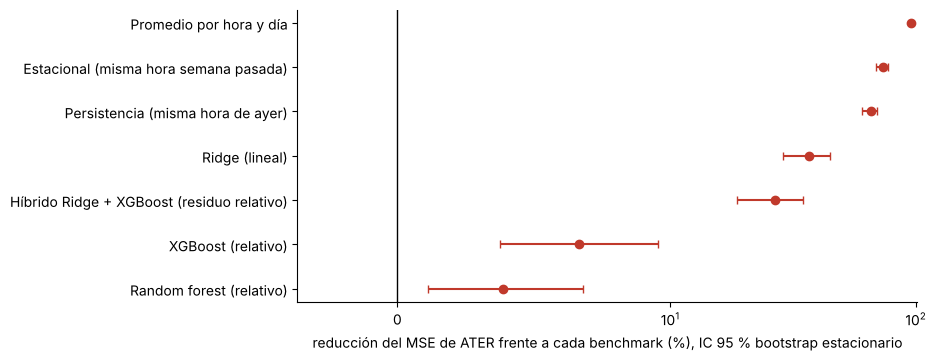

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8)); e = ef.sort_values("mejora_MSE_pct")
ax.errorbar(e.mejora_MSE_pct, e.benchmark, xerr=[e.mejora_MSE_pct - e.IC95_lo, e.IC95_hi - e.mejora_MSE_pct], fmt="o", color="#C0392B", capsize=3)
ax.axvline(0, color="k", lw=1); ax.set_xscale("symlog", linthresh=10); ax.set_xlabel("reducción del MSE de ATER frente a cada benchmark (%), IC 95 % bootstrap estacionario")
plt.show()

In [10]:
sem = pd.read_csv(R + "orig_semillas.csv"); print("Robustez ante la semilla de los expertos aleatorios (prueba):"); sem.round(1)

Robustez ante la semilla de los expertos aleatorios (prueba):


semilla,MSE_ATER,MSE_Random forest (relativo),MSE_XGBoost (relativo),mejora_vs_RF_%
2.026,2256.100000,2347.100000,2416.900000,3.900000
7,2265.800000,2352.700000,2434.500000,3.700000
42,2264.100000,2350.700000,2421.000000,3.700000
123,2259.700000,2344.700000,2423.400000,3.600000
999,2257.500000,2349.200000,2425.400000,3.900000


Meses en que ATER tiene menos MSE que el RF: 18 de 22
               MAPE_ATER  MAPE_RF    horas
tipo de día                               
festivo             3.34     3.72    768.0
fin de semana       2.69     2.84   4440.0
laboral             2.26     2.33  10464.0 

              MAPE_ATER  MAPE_RF   horas
calor                                   
caluroso           2.66     2.78  3918.0
frío               1.94     1.97  3918.0
muy caluroso       2.87     3.01  3918.0
templado           2.28     2.42  3918.0 



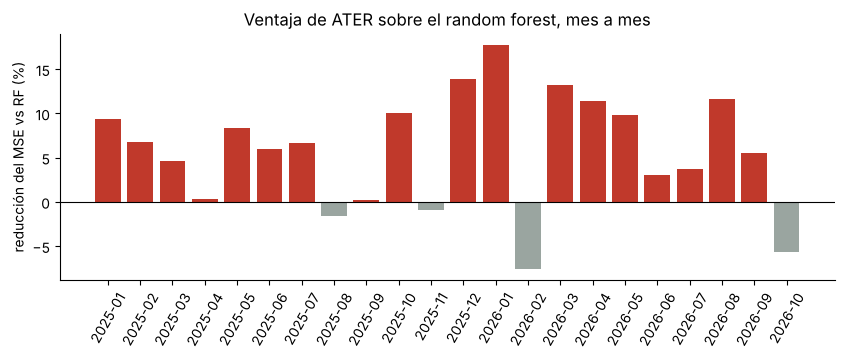

In [11]:
# ¿Dónde NO gana ATER? Error por mes y por segmento frente al random forest relativo
import pipeline_energia as P
pt = pd.read_pickle(R + "pred_prueba_con_original.pkl"); df = pd.read_pickle(R + "datos_horarios.pkl"); X, y = P.construir(df); Xt = X.loc[pt.index]
RF = "Random forest (relativo)"
mes = pt.groupby(pt.index.to_period("M")).apply(lambda d: 100 * (1 - np.mean((d.y - d[ORIG]) ** 2) / np.mean((d.y - d[RF]) ** 2)))
print("Meses en que ATER tiene menos MSE que el RF: %d de %d" % ((mes > 0).sum(), len(mes)))
seg = pd.DataFrame({"tipo de día": np.where(Xt.festivo == 1, "festivo", np.where(Xt.dow >= 5, "fin de semana", "laboral")),
                    "calor": pd.qcut(Xt.calor, 4, labels=["frío", "templado", "caluroso", "muy caluroso"]).astype(str)}, index=pt.index)
for c in seg:
    print(pt.groupby(seg[c]).apply(lambda d: pd.Series({"MAPE_ATER": 100 * np.mean(np.abs(d.y - d[ORIG]) / d.y), "MAPE_RF": 100 * np.mean(np.abs(d.y - d[RF]) / d.y), "horas": len(d)})).round(2), "\n")
fig, ax = plt.subplots(figsize=(10, 3.2)); ax.bar(mes.index.astype(str), mes.values, color=np.where(mes > 0, "#C0392B", "#9AA5A0"))
ax.axhline(0, color="k", lw=.8); ax.set_ylabel("reducción del MSE vs RF (%)"); ax.tick_params(axis="x", rotation=60); ax.set_title("Ventaja de ATER sobre el random forest, mes a mes"); plt.show()

**Dónde no gana.** ATER tiene menor MAPE que el random forest en todos los tipos de día y en los cuatro cuartiles de calor. La ventaja es mayor en los festivos (3,34 % frente a 3,72 %), donde la corrección de nivel en línea ayuda más, y casi nula en las horas frías (1,94 % frente a 1,97 %). Mes a mes pierde en 4 de 22 meses: la ventaja es pequeña y no es uniforme.

## Tiempos de cómputo

Los tiempos de todos los modelos se midieron **en la misma máquina (2 núcleos) y con los mismos datos** con `src/tiempos_computo.py`:

* **búsqueda de hiperparámetros:** la registrada en la validación anidada del Entregable 2 para los 7 modelos vistos en clase, y la de Optuna para ATER (4 folds externos × 60 ensayos + 80 ensayos finales), medida de nuevo;
* **entrenamiento final:** ajuste con las 36.552 horas de entrenamiento;
* **inferencia:** pronóstico de las 15.672 horas de la prueba;
* **pronóstico de un día:** las 24 horas de un día, mediana de 5 repeticiones (lo que se hace cada noche en operación).

In [12]:
tc = pd.read_csv(R + "tiempos_computo.csv")
tc = tc.assign(pronostico_dia_ms=tc.pronostico_dia_s * 1000).drop(columns=["pronostico_dia_s", "nucleos"])
tc.columns = ["modelo", "grupo", "optimizador", "búsqueda (s)", "entrenamiento final (s)", "inferencia 15.672 h (s)", "pronóstico de 1 día (ms)"]
tc.sort_values("entrenamiento final (s)", ascending=False)

modelo,grupo,optimizador,búsqueda (s),entrenamiento final (s),inferencia 15.672 h (s),pronóstico de 1 día (ms)
ATER (modelo original),Original,Bayesiano (Optuna TPE),"22,6","34,98","0,72","88,43"
Random forest (relativo),Benchmark del proyecto,Grid (validación),,"31,23","0,43","67,50"
Random Forest (E2),Visto en clase (E2),Grid Search,"147,3","10,07","0,24","10,19"
Híbrido Ridge + XGBoost (residuo relativo),Benchmark del proyecto,Grid (validación),,"3,95","0,07","13,60"
SVR (E2),Visto en clase (E2),Grid Search,"20,3","2,46","0,09","3,92"
XGBoost (relativo),Benchmark del proyecto,Grid (validación),,"1,97","0,07","4,65"
XGBoost (E2),Visto en clase (E2),Random Search,"88,9","1,72","0,08","4,27"
Decision Tree (E2),Visto en clase (E2),Bayesiano (Optuna TPE),"7,9","0,45","0,01","3,23"
Ridge (lineal),Benchmark del proyecto,Grid (validación),,"0,28","0,02","3,18"
Lasso (E2),Visto en clase (E2),Grid Search,"5,1","0,05","0,01","2,96"


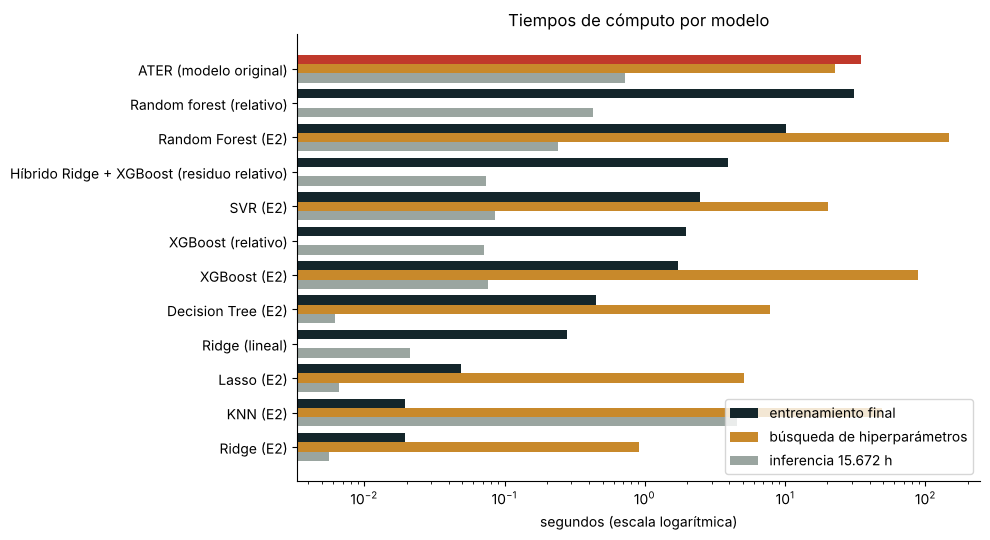

In [13]:
g = tc[tc.grupo != "Tradicional"].sort_values("entrenamiento final (s)")
fig, ax = plt.subplots(figsize=(10, 5.5)); yy = np.arange(len(g)); h = 0.27
ax.barh(yy + h, g["entrenamiento final (s)"], h, color=[ "#C0392B" if m.startswith("ATER") else "#14262B" for m in g.modelo], label="entrenamiento final")
ax.barh(yy, g["búsqueda (s)"].fillna(0), h, color="#C8892B", label="búsqueda de hiperparámetros")
ax.barh(yy - h, g["inferencia 15.672 h (s)"], h, color="#9AA5A0", label="inferencia 15.672 h")
ax.set_yticks(yy, g.modelo); ax.set_xscale("log"); ax.set_xlabel("segundos (escala logarítmica)"); ax.legend(loc="lower right")
ax.set_title("Tiempos de cómputo por modelo"); plt.tight_layout(); plt.show()

**Lectura.** Entrenar ATER completo toma unos 35 s y casi todo ese tiempo es entrenar a sus cinco expertos (solo el random forest relativo toma 31 s); el núcleo de combinación es una sola pasada y tarda décimas de segundo. Su búsqueda de hiperparámetros (unos 23 s) es más corta que la del random forest (147 s) o la del XGBoost (89 s) del Entregable 2, porque cada ensayo de Optuna solo recombina pronósticos ya calculados; no incluye la validación de los expertos, que se reutiliza de los benchmarks. Una vez entrenado, ATER pronostica las 24 horas del día siguiente en menos de una décima de segundo: el límite en operación es la publicación de los datos, no el cómputo.

## Veredicto de superioridad (sección 6.1 de la guía)

In [14]:
ver = json.load(open(R + "orig_veredicto.json")); print(json.dumps(ver, indent=1, ensure_ascii=False))

{
 "mejor_benchmark": "Random forest (relativo)",
 "condicion1_metrica_media_mejor": true,
 "pruebas_que_rechazan_vs_mejor_benchmark": [
  "Diebold-Mariano (HLN)",
  "Giacomini-White condicional",
  "Wilcoxon de rangos con signo",
  "MCS (único sobreviviente)"
 ],
 "n_pruebas_rechazan": 4,
 "condicion2_tres_pruebas": true,
 "delta_cliff_pareado": 0.2526799387442573,
 "delta_cliff_no_pareado": 0.072782234896543,
 "d_cohen": 0.11913328798205511,
 "efecto_con_medidas_no_pareadas": "despreciable",
 "condicion3_efecto_no_despreciable": true,
 "R3": true,
 "mcs_incluidos": [
  "ATER (modelo original)"
 ],
 "ida_y_vuelta": true,
 "ida_y_vuelta_max_dif_MWh": 1.1368683772161603e-12,
 "hiperparametros": {
  "eta": 89.38423554574598,
  "lam": 0.9657109024109057,
  "sigma": 5.068873602673464,
  "eta_b": 0.00796538678948261
 }
}


**Veredicto.**

1. **Métrica media mejor que todos los benchmarks:** sí, en la validación anidada (MSE 2.097 ± 821 frente a 2.210 ± 759 del híbrido, el mejor benchmark ahí) y en la prueba (2.256 frente a 2.347 del random forest relativo).
2. **Al menos tres pruebas rechazan la igualdad con p ajustado < 0,05:** sí, frente a los 7 benchmarks. Frente al mejor (random forest relativo): Diebold-Mariano HLN p ajustado = 0,004, Giacomini-White p ajustado = 0,003, Wilcoxon p ajustado < 0,001, y el MCS deja a ATER como **único** modelo superior (p del RF = 0,005).
3. **Tamaño del efecto no despreciable:** frente a los tradicionales, Ridge y el híbrido el efecto es mediano o grande con cualquier medida. Frente a los árboles relativos es **pequeño**: el δ de Cliff **pareado** (mismo día) es 0,25 frente al RF y 0,22 frente al XGBoost (umbral 0,147), y ATER gana el 62,6 % y el 61,1 % de los días. Con el δ de Cliff **no pareado** (0,07) y la d de Cohen (0,12) el efecto sería despreciable. Como todas las pruebas son pareadas por día, la medida que corresponde es la pareada; se reportan las tres para que el lector juzgue.

**Conclusión:** ATER es **estadísticamente superior** a todos los benchmarks (R3), con una ventaja práctica grande frente a los métodos tradicionales (65 % menos MSE que la persistencia) y **pequeña pero consistente** frente a los mejores árboles (3,9 % menos MSE que el random forest relativo, IC 95 %: 1,1–6,8 %; entre 3,6 y 3,9 % en las 5 semillas probadas y en 18 de 22 meses).